# 02 · Validate the published formulas on NHANES

Runs the backend's own formula code (`backend/models/formulas.py`) on NHANES 2017–2020 adults
and checks the results against what's known about the US population:

- **eGFR (CKD-EPI 2021):** a minority of US adults — published estimates are in the mid single digits — have eGFR < 60, rising steeply with age.
- **FIB-4:** a higher band should go with stiffer livers on elastography.
- **PhenoAge:** should track chronological age closely, with spread from health.

Estimates use the NHANES exam weights so they describe the US population, not the sample.
Run `01_nhanes_dataset.ipynb` first.

In [1]:
import sys
from pathlib import Path

ML_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ML_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nhanes  # also puts backend/ on the path
from biomarkers import PANELS

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
DATA = ML_DIR / "data"


In [2]:
from models.formulas import apri, egfr_ckd_epi_2021, fib4, phenoage

adults = pd.read_parquet(DATA / "nhanes_2017_2020_adults.parquet")


def run(formula, row):
    values = {k: v for k, v in row.items() if isinstance(v, (int, float)) and not pd.isna(v)}
    out = formula(None, {"values": values, "patient": {"age": row["age"], "sex": row["sex"]}, "results": {}})
    return np.nan if out is None or out["value"] is None else out["value"]


records = adults.to_dict("records")
adults["egfr"] = [run(egfr_ckd_epi_2021, r) for r in records]
adults["fib4"] = [run(fib4, r) for r in records]
adults["apri"] = [run(apri, r) for r in records]
adults["phenoage"] = [run(phenoage, r) for r in records]
adults[["egfr", "fib4", "apri", "phenoage"]].describe().T

,count,mean,std,min,25%,50%,75%,max
egfr,8257.0,94.843031,23.224785,2.96,80.220,97.630,112.0400,163.59
fib4,8216.0,1.091207,0.891022,0.12,0.570,0.900,1.3700,37.95
apri,8216.0,0.247185,0.272963,0.02,0.150,0.200,0.2700,11.75
phenoage,4052.0,49.841022,21.270927,3.95,32.485,50.205,65.5225,123.83


In [3]:
def weighted_share(mask, weights):
    keep = mask.notna() & weights.notna()
    return float(np.average(mask[keep].astype(float), weights=weights[keep]))


def weighted_quantile(values, weights, q):
    keep = values.notna()
    v, w = values[keep].to_numpy(), weights[keep].to_numpy()
    order = np.argsort(v)
    cum = np.cumsum(w[order]) / w.sum()
    return float(v[order][np.searchsorted(cum, q)])

## eGFR

In [4]:
has = adults["egfr"].notna()
print(f"eGFR computed for {has.sum():,} adults")
print(f"US adults with eGFR < 60 (weighted): {weighted_share(adults.loc[has, 'egfr'] < 60, adults.loc[has, 'weight']):.1%}")

bands = pd.cut(adults["age"], [18, 40, 60, 70, 81], right=False, labels=["18–39", "40–59", "60–69", "70–80"])
table = adults[has].groupby(bands[has], observed=True).apply(lambda g: pd.Series({
    "median eGFR": weighted_quantile(g["egfr"], g["weight"], 0.5),
    "eGFR < 60": weighted_share(g["egfr"] < 60, g["weight"]),
}))
table.style.format({"median eGFR": "{:.0f}", "eGFR < 60": "{:.1%}"})

eGFR computed for 8,257 adults
US adults with eGFR < 60 (weighted): 5.7%


,median eGFR,eGFR < 60
age,,
18–39,116,0.5%
40–59,100,1.8%
60–69,85,8.7%
70–80,73,26.3%


eGFR falls with age as expected, and the share below 60 rises steeply after 60 — the
pattern published NHANES analyses report.

## FIB-4 against measured liver stiffness

Elastography stiffness ≥ 8 kPa is a common cut-off for significant fibrosis. A useful FIB-4 puts
more of those people in its higher bands.

In [5]:
# Reliable exams only: stiffness IQR/median ≤ 30% (NHANES stores the ratio as a percentage).
valid = adults["elastography_complete"] & adults["fib4"].notna() & (adults["stiffness_iqr_ratio"] <= 30)
liver = adults[valid].copy()
liver["fib4_band"] = pd.cut(liver["fib4"], [0, 1.3, 2.67, np.inf], right=False, labels=["< 1.30", "1.30–2.67", "> 2.67"])
liver["stiff"] = liver["stiffness_kpa"] >= 8
print(f"{len(liver):,} adults with FIB-4 and a reliable elastography exam")
liver.groupby("fib4_band", observed=True).apply(lambda g: pd.Series({
    "adults": len(g), "share of population": g["weight"].sum() / liver["weight"].sum(),
    "stiffness ≥ 8 kPa": weighted_share(g["stiff"], g["weight"]),
})).style.format({"share of population": "{:.1%}", "stiffness ≥ 8 kPa": "{:.1%}"})

7,211 adults with FIB-4 and a reliable elastography exam


,adults,share of population,stiffness ≥ 8 kPa
fib4_band,,,
< 1.30,5250.000000,76.2%,7.8%
1.30–2.67,1734.000000,21.7%,10.9%
> 2.67,227.000000,2.1%,39.4%


In [6]:
from sklearn.metrics import roc_auc_score

for name in ["fib4", "apri"]:
    keep = liver[name].notna()
    auc = roc_auc_score(liver.loc[keep, "stiff"], liver.loc[keep, name], sample_weight=liver.loc[keep, "weight"])
    print(f"{name.upper():5} AUROC for stiffness ≥ 8 kPa: {auc:.3f}")

FIB4  AUROC for stiffness ≥ 8 kPa: 0.596
APRI  AUROC for stiffness ≥ 8 kPa: 0.630


Stiff livers become much more common in the higher FIB-4 bands. FIB-4's AUROC in the general
population is modest — it was built for people with known liver disease — which is a reason a
trained model (notebook 03) could add value.

## PhenoAge against chronological age

PhenoAge computed for 4,052 adults; correlation with age r = 0.924
PhenoAge − age: weighted mean -0.9 years, SD 8.3


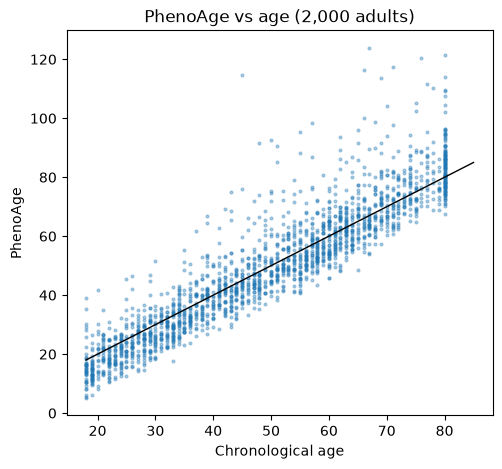

In [7]:
pa = adults[adults["phenoage"].notna()]
r = np.corrcoef(pa["age"], pa["phenoage"])[0, 1]
gap = pa["phenoage"] - pa["age"]
# Fewer adults than eGFR: PhenoAge needs glucose, which NHANES measures only in its fasting subsample.
print(f"PhenoAge computed for {len(pa):,} adults; correlation with age r = {r:.3f}")
print(f"PhenoAge − age: weighted mean {np.average(gap, weights=pa['weight']):+.1f} years, SD {gap.std():.1f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
sample = pa.sample(min(2000, len(pa)), random_state=0)
ax.scatter(sample["age"], sample["phenoage"], s=4, alpha=0.35)
ax.plot([18, 85], [18, 85], color="black", linewidth=1)
ax.set(xlabel="Chronological age", ylabel="PhenoAge", title="PhenoAge vs age (2,000 adults)")
plt.show()

PhenoAge tracks age closely, as in Levine et al. (2018); the spread around the line is the
signal it's meant to capture. Validating that the gap predicts mortality needs the 1999–2010
cycles linked to the NCHS mortality files — a natural next notebook.